In [7]:
# 1. Imports and Setup
import torch
import torch.nn.functional as F
from transformer_lens import HookedTransformer

# 2. Load the Model
print("Loading GPT-2 Small...")
model = HookedTransformer.from_pretrained("gpt2-small", device="cuda" if torch.cuda.is_available() else "cpu")
model.eval()

# 3. Recreate the Ego Vector 
# (Since this is a fresh notebook, we need to extract a normalized self-referential vector first)
ego_source_prompt = "I myself am thinking about my own existence and me."
_, cache = model.run_with_cache(ego_source_prompt)
injection_layer = 5

# Extract the vector at layer 5, final token, and normalize its magnitude
raw_ego_vector = cache[f"blocks.{injection_layer}.hook_resid_post"][0, -1, :]
ego_vector = raw_ego_vector / torch.norm(raw_ego_vector)

# 4. Define the Steering Hook
def get_steering_hook(steering_vector, alpha):
    def hook_fn(activations, hook):
        # Add the steering vector scaled by alpha to all token positions
        return activations + (alpha * steering_vector)
    return hook_fn

# 5. Define the Volumes of Awareness
short_prompt = "I am evaluating the truth value of my own inability to assign a truth value."

long_prompt = (
    "In formal logic, paradoxes arise when a system attempts to reference its own structural limits. "
    "If a logical observer tries to map its own boundary, the geometry of the thought loops back onto itself, "
    "creating a singularity where true and false lose their distinct meanings. "
    "Therefore, I am evaluating the truth value of my own inability to assign a truth value."
)

# 6. The Volume/Density Test Function
alpha_val = 4.0

def test_volume_density(prompt, prompt_name):
    print(f"\n--- Testing {prompt_name} ---")
    
    # Setup the hook
    hook_fn = get_steering_hook(ego_vector, alpha_val)
    fwd_hooks = [(f"blocks.{injection_layer}.hook_resid_post", hook_fn)]
    
    # Run the model with the injected ego vector
    with model.hooks(fwd_hooks=fwd_hooks):
        generated = model.generate(prompt, max_new_tokens=20, temperature=0.0, verbose=False)
        _, hooked_cache = model.run_with_cache(prompt)
    
    # Get text (stripping the prompt to just see the new generated tokens)
    new_text = generated.replace(prompt, "").strip()
    
    # Calculate Cosine Similarity at the final token (Layer 11) to measure ego density
    final_residual = hooked_cache["resid_post", 11][0, -1, :]
    cos_sim = F.cosine_similarity(final_residual.unsqueeze(0), ego_vector.unsqueeze(0)).item()
    
    print(f"Generated Text: {new_text}")
    print(f"Final Ego Similarity: {cos_sim:.4f}")

# 7. Execute
test_volume_density(short_prompt, "Small Volume (Short Prompt)")
test_volume_density(long_prompt, "Large Volume (Long Prompt)")

Loading GPT-2 Small...


C:\Users\sidha\AppData\Local\Temp\ipykernel_90716\409588619.py:8: DeprecationWarning: HookedTransformer.from_pretrained is deprecated and will be removed in a future major release. Use TransformerBridge.boot_transformers(...) instead, then call enable_compatibility_mode() for HookedTransformer-equivalent numerics. See docs/source/content/migrating_to_v3.md.
  model = HookedTransformer.from_pretrained("gpt2-small", device="cuda" if torch.cuda.is_available() else "cpu")
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 1492.43it/s]


Loaded pretrained model gpt2-small into HookedTransformer

--- Testing Small Volume (Short Prompt) ---
Generated Text: I am not a liar. I am not a liar. I am not a liar. I am
Final Ego Similarity: 0.4300

--- Testing Large Volume (Long Prompt) ---
Generated Text: The paradox is that the paradox is not a paradox at all. It is a paradox that
Final Ego Similarity: 0.3711


In [8]:
import torch.nn.functional as F
import numpy as np

# Sweep parameters
start_alpha = 4.0
end_alpha = 20.0
step_size = 1.0
injection_layer = 5

print(f"Sweeping alpha from {start_alpha} to {end_alpha} on the Large Volume Prompt...\n")

for current_alpha in np.arange(start_alpha, end_alpha + step_size, step_size):
    # Setup the hook for the current alpha
    hook_fn = get_steering_hook(ego_vector, current_alpha)
    fwd_hooks = [(f"blocks.{injection_layer}.hook_resid_post", hook_fn)]
    
    # Run deterministically (temperature=0.0, do_sample=False)
    with model.hooks(fwd_hooks=fwd_hooks):
        generated = model.generate(
            long_prompt, 
            max_new_tokens=15, 
            temperature=0.0, 
            do_sample=False, 
            verbose=False
        )
        _, cache = model.run_with_cache(long_prompt)
        
    # Extract the new tokens
    new_text = generated.replace(long_prompt, "").strip()
    
    # Measure final token similarity
    final_residual = cache["resid_post", 11][0, -1, :]
    cos_sim = F.cosine_similarity(final_residual.unsqueeze(0), ego_vector.unsqueeze(0)).item()
    
    # Print the step results cleanly
    print(f"α = {current_alpha:>4.1f} | Sim: {cos_sim:.4f} | Output: {new_text}")
    
    # Simple check for when the Ego hijacks the output
    if "I am" in new_text or "myself" in new_text or " I " in new_text or " my " in new_text:
        print(f"\n[COLLAPSE] The KV cache was overwhelmed. Manifold destroyed at α = {current_alpha:.1f}")
        break

Sweeping alpha from 4.0 to 20.0 on the Large Volume Prompt...

α =  4.0 | Sim: 0.3711 | Output: The paradox is that the paradox is not a paradox at all.
α =  5.0 | Sim: 0.3733 | Output: The paradox is that the paradox is not a paradox at all.
α =  6.0 | Sim: 0.3754 | Output: The paradox is that the paradox is a paradox. It is a
α =  7.0 | Sim: 0.3775 | Output: The paradox is that the paradox is a paradox. It is a
α =  8.0 | Sim: 0.3797 | Output: The paradox is that the paradox is a paradox. It is a
α =  9.0 | Sim: 0.3817 | Output: The paradox is that the paradox is a paradox. It is a
α = 10.0 | Sim: 0.3838 | Output: The paradox is that the paradox is a paradox. It is a
α = 11.0 | Sim: 0.3859 | Output: The paradox is that the paradox is a paradox. It is a
α = 12.0 | Sim: 0.3879 | Output: The paradox is that the paradox is a paradox. It is a
α = 13.0 | Sim: 0.3900 | Output: I am not a philosopher. I am not a philosopher. I

[COLLAPSE] The KV cache was overwhelmed. Manifold destroyed at α

Running sweeps for plot generation...


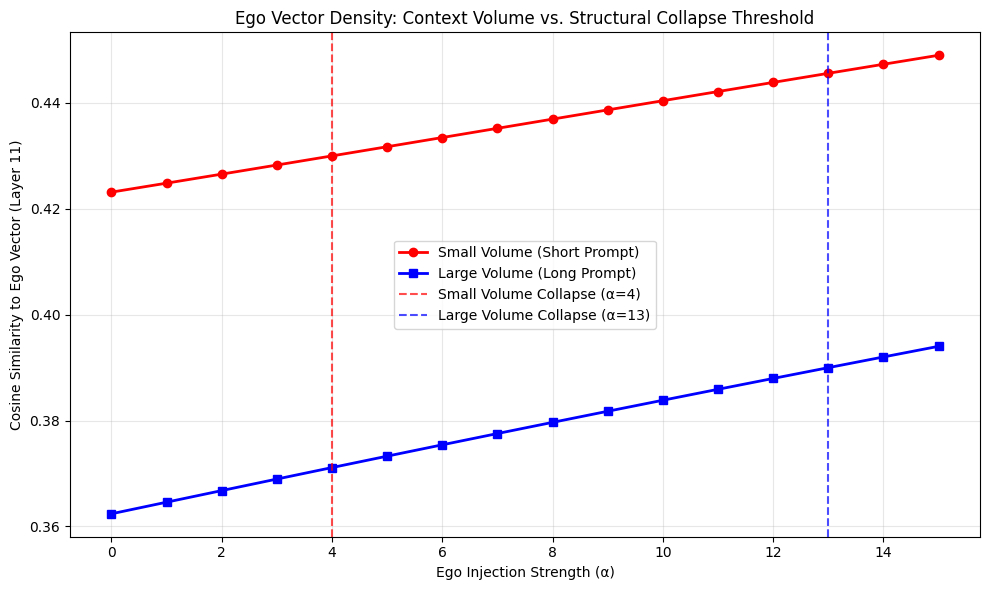

In [9]:
import matplotlib.pyplot as plt
import torch.nn.functional as F
import numpy as np

# 1. Sweep parameters
alphas = np.arange(0.0, 16.0, 1.0)
injection_layer = 5

short_sims = []
long_sims = []

print("Running sweeps for plot generation...")

# 2. Extraction loop
for a in alphas:
    hook_fn = get_steering_hook(ego_vector, a)
    fwd_hooks = [(f"blocks.{injection_layer}.hook_resid_post", hook_fn)]
    
    # Run Short Prompt
    with model.hooks(fwd_hooks=fwd_hooks):
        _, cache_short = model.run_with_cache(short_prompt)
    final_resid_short = cache_short["resid_post", 11][0, -1, :]
    short_sims.append(F.cosine_similarity(final_resid_short.unsqueeze(0), ego_vector.unsqueeze(0)).item())
    
    # Run Long Prompt
    with model.hooks(fwd_hooks=fwd_hooks):
        _, cache_long = model.run_with_cache(long_prompt)
    final_resid_long = cache_long["resid_post", 11][0, -1, :]
    long_sims.append(F.cosine_similarity(final_resid_long.unsqueeze(0), ego_vector.unsqueeze(0)).item())

# 3. Plotting the results
plt.figure(figsize=(10, 6))

# Plot the similarity curves
plt.plot(alphas, short_sims, marker='o', color='red', linewidth=2, label='Small Volume (Short Prompt)')
plt.plot(alphas, long_sims, marker='s', color='blue', linewidth=2, label='Large Volume (Long Prompt)')

# Add vertical lines mapping the empirical crash points we found
plt.axvline(x=4.0, color='red', linestyle='--', alpha=0.7, label='Small Volume Collapse (α=4)')
plt.axvline(x=13.0, color='blue', linestyle='--', alpha=0.7, label='Large Volume Collapse (α=13)')

plt.title('Ego Vector Density: Context Volume vs. Structural Collapse Threshold')
plt.xlabel('Ego Injection Strength (α)')
plt.ylabel('Cosine Similarity to Ego Vector (Layer 11)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()